# Supervisor Code Tour: `FilterSafe-8` & Safety-Aware Uncertainty Quantification

**Master's Thesis (BTU Cottbus-Senftenberg, M.Sc. AI, Module 13600)**  
**Author:** Hosam Shibly | **Sealed Core Commit:** `5e458c1` | **Frozen Stage 4 Archive:** `af33a83e157f7d2e`

This 5-cell executable tour imports directly from the frozen `paper_workspace/src/` and `thesis/` modules (113/113 SHA-256 verified) and runs end-to-end on synthetic 24 GHz signals plus the tracked NICU Anchor Session `7.3` (`25 min`, 736 windows):

1. Inspect the frozen 8-parameter `FilterSafe-8` (`R2e`) model.
2. Verify analytical BPTT gradients, $SO(2)\times\mathbb{R}_{>0}$ baseband invariance, causality, and $+10\text{ bpm}$ translation equivariance.
3. Track NICU Anchor Session `7.3` live and visualize `FilterSafe-8` vs. memoryless `R0` and causal uncertainty (`U2`, `U6b`).
4. Inspect the `U6b` pause-safe vs. WGN OOD separation and the finite-$K$ conformal vacuity curve ($K_{\mathrm{cal}}=10$ vs. $K_{\mathrm{cal}}\ge 19$).
5. Summarize the audited Stage 2-4 headline tables directly from the immutable JSON artifacts.

In [1]:
import hashlib, math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from paper_workspace.src import config as C
from paper_workspace.src.data_loader import load_radar
from paper_workspace.src.demod import csd
from paper_workspace.src.filtering import autocorr_coarse, bandpass
from paper_workspace.src.hpss import mitigate_hpss
from thesis import diff_hmm_and_foils as D
from thesis import io_utils as IO
from thesis import viterbi_tracker as VT
from thesis import wp3_wp4_uncertainty_conformal as UQ

arch = ROOT / "thesis" / "outputs" / "stage3_uncertainty" / "frozen_stage4_models.npz"
sha = hashlib.sha256(arch.read_bytes()).hexdigest()
bundle = np.load(arch, allow_pickle=True)

r2e = D.DifferentiableSymmetricHMM(mode="linear_filtersafe", decoder="causal_forward")
r2e.theta = np.asarray(bundle["r2e_full_refit_theta"], dtype=np.float64).copy()
print(f"Archive SHA-256 : {sha}")
print(f"n_params        : {r2e.n_params}")
for k, v in r2e.interpretable_params().items():
    print(f"  {k:<16s}: {v:+.4f}" if k.startswith("w") else f"  {k:<16s}: {v:.4f}")

Archive SHA-256 : af33a83e157f7d2efb0f47e50c9544ee19bacb7da88ab0e0235ccead029cbcc4
n_params        : 8
  w1_p1_clean     : +2.0000
  w2_p2_harm      : +0.0000
  w3_p3_harm      : +0.0000
  w4_phalf_sub    : +0.0000
  w5_anchor       : +3.9951
  w6_p1_raw       : -0.5000
  sigma_slow_bpm  : 1.0000
  sigma_jump_bpm  : 5.0000
  pi_jump         : 0.0009
  k1              : 0.0000
  k2              : 0.0000


In [2]:
# Analytical BPTT vs. finite differences + SO(2)xR+ + causality + +10 bpm equivariance
rng = np.random.default_rng(2026)
phi_toy = rng.normal(-2.0, 0.8, size=(10, VT.BR_GRID_1BPM.size, D.N_SAL_CHANNELS))
ref_toy = rng.uniform(28.0, 62.0, size=10)
vm_toy = np.ones(10, dtype=bool)
th = np.clip(r2e.theta.copy(), [b[0] + 1e-3 for b in r2e.bounds], [b[1] - 1e-3 for b in r2e.bounds])
_, g_ana = r2e.loss_and_grad(th, [(phi_toy, ref_toy, vm_toy)])
h = 1e-6
g_fd = np.zeros_like(th)
for j in range(th.size):
    tp, tm = th.copy(), th.copy()
    tp[j] += h; tm[j] -= h
    lp, _ = r2e.loss_and_grad(tp, [(phi_toy, ref_toy, vm_toy)])
    lm, _ = r2e.loss_and_grad(tm, [(phi_toy, ref_toy, vm_toy)])
    g_fd[j] = (lp - lm) / (2.0 * h)
print(f"BPTT vs. central FD max diff   : {np.max(np.abs(g_ana - g_fd)):.3e}")

wide = np.arange(-60.0, 180.0 + 1e-9, 1.0)
pb = np.zeros((6, wide.size, D.N_SAL_CHANNELS))
ps = np.zeros((6, wide.size, D.N_SAL_CHANNELS))
for ch in range(D.N_SAL_CHANNELS):
    sw = 2.5 + 0.5 * (ch == 4)
    pb[:, :, ch] = np.log(np.exp(-0.5 * ((wide[None, :] - 36.0) / sw) ** 2) + 1e-12)
    ps[:, :, ch] = np.log(np.exp(-0.5 * ((wide[None, :] - 46.0) / sw) ** 2) + 1e-12)
eq_err = np.max(np.abs((r2e.predict_session(ps, wide)["est_mmse"] - r2e.predict_session(pb, wide)["est_mmse"]) - 10.0))
phi_p = phi_toy.copy()
phi_p[6:] = rng.normal(-2.0, 2.0, size=(4, VT.BR_GRID_1BPM.size, D.N_SAL_CHANNELS))
caus_err = np.max(np.abs(r2e.predict_session(phi_toy)["est_mmse"][:6] - r2e.predict_session(phi_p)["est_mmse"][:6]))
print(f"+10 bpm translation eq. error  : {eq_err:.3e} bpm")
print(f"Causal future perturbation diff: {caus_err:.1f}")

BPTT vs. central FD max diff   : 4.462e-09
+10 bpm translation eq. error  : 1.421e-14 bpm
Causal future perturbation diff: 0.0


Anchor Session 7.3 (1 Hz ref) -> R0 RMSE: 4.789 bpm | R2e FilterSafe-8 RMSE: 4.050 bpm


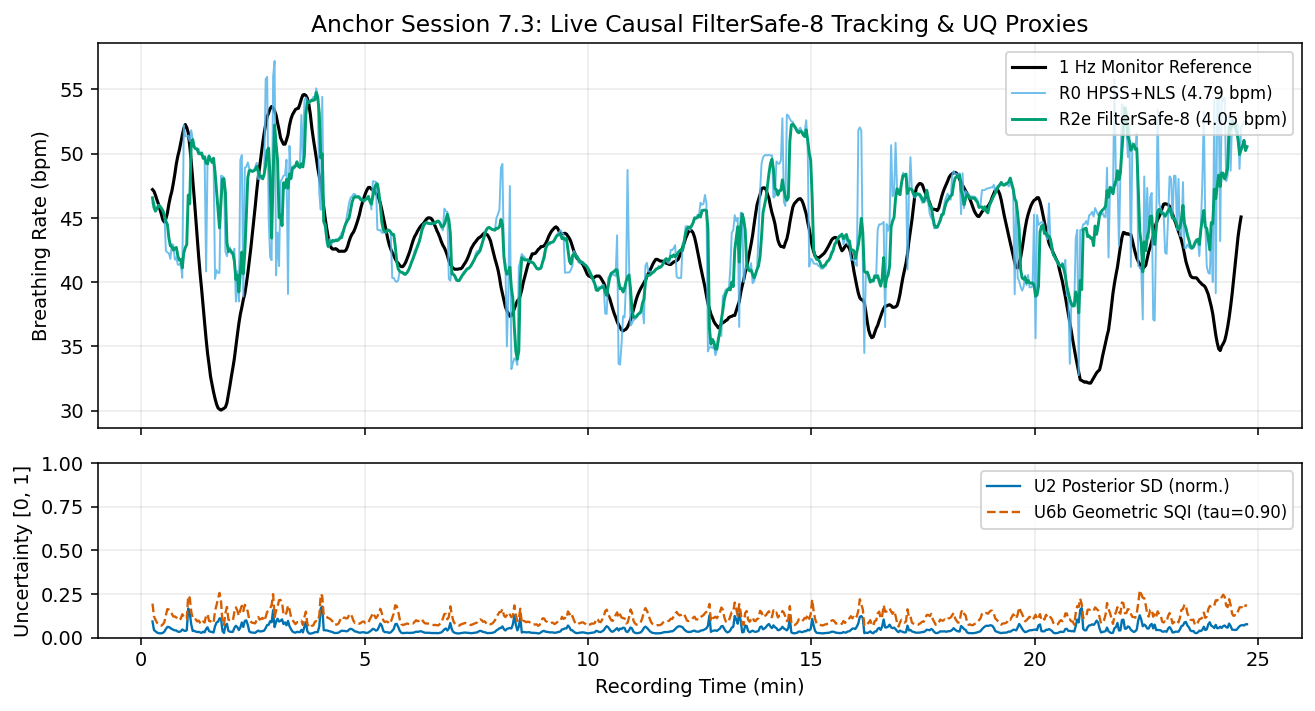

In [3]:
# Live run on preterm NICU Anchor Session 7.3 (tracked in beltrao_data/)
bi, bq = load_radar("7.3")
c73 = IO.load_locked_cache("7.3")
valid = np.asarray(c73["valid"], dtype=bool)
ref_1hz = np.asarray(c73["ref"], dtype=np.float64)
r0_pred = np.asarray(c73["est_hpss"], dtype=np.float64)

n_win = len(r0_pred)
step = int(C.UPDATE_S * C.FS_RADAR)
phi_73 = np.empty((n_win, VT.BR_GRID_1BPM.size, D.N_SAL_CHANNELS), dtype=np.float64)
for idx in range(n_win):
    s0 = idx * step
    dr = bandpass(csd(bi[s0 : s0 + C.WIN_SAMPLES], bq[s0 : s0 + C.WIN_SAMPLES]))
    dc = bandpass(mitigate_hpss(dr)["x_hat"])
    phi_73[idx] = D.extract_salience_features_window(dr, dc, autocorr_coarse(dc), VT.BR_GRID_1BPM)

preds_73 = r2e.predict_session(phi_73)
r2e_pred = preds_73["est_mmse"]
u_73 = UQ.extract_zero_tuned_proxies_session(phi_73, preds_73["post_entropy"], preds_73["post_sd_bpm"])

t_min = (np.arange(n_win) * C.UPDATE_S + C.WIN_S / 2.0) / 60.0
rmse_r0 = np.sqrt(np.mean((r0_pred[valid] - ref_1hz[valid]) ** 2))
rmse_r2e = np.sqrt(np.mean((r2e_pred[valid] - ref_1hz[valid]) ** 2))
print(f"Anchor Session 7.3 (1 Hz ref) -> R0 RMSE: {rmse_r0:.3f} bpm | R2e FilterSafe-8 RMSE: {rmse_r2e:.3f} bpm")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9.5, 5.2), sharex=True, gridspec_kw={"height_ratios": [2.2, 1.0]})
ax1.plot(t_min, ref_1hz, color="#000000", lw=1.6, label="1 Hz Monitor Reference")
ax1.plot(t_min, r0_pred, color="#56B4E9", lw=1.0, alpha=0.85, label=f"R0 HPSS+NLS ({rmse_r0:.2f} bpm)")
ax1.plot(t_min, r2e_pred, color="#009E73", lw=1.5, label=f"R2e FilterSafe-8 ({rmse_r2e:.2f} bpm)")
ax1.set_ylabel("Breathing Rate (bpm)")
ax1.set_title("Anchor Session 7.3: Live Causal FilterSafe-8 Tracking & UQ Proxies")
ax1.legend(loc="upper right", frameon=True, fontsize=8.5)
ax1.grid(alpha=0.25)

ax2.plot(t_min, u_73["U2_Posterior_SD"], color="#0072B2", lw=1.2, label="U2 Posterior SD (norm.)")
ax2.plot(t_min, u_73["U6b_ZeroTuned_Geometric_SQI"], color="#D55E00", lw=1.2, ls="--", label="U6b Geometric SQI (tau=0.90)")
ax2.set_xlabel("Recording Time (min)")
ax2.set_ylabel("Uncertainty [0, 1]")
ax2.set_ylim(0.0, 1.0)
ax2.legend(loc="upper right", frameon=True, fontsize=8.5)
ax2.grid(alpha=0.25)
plt.tight_layout()
plt.show()

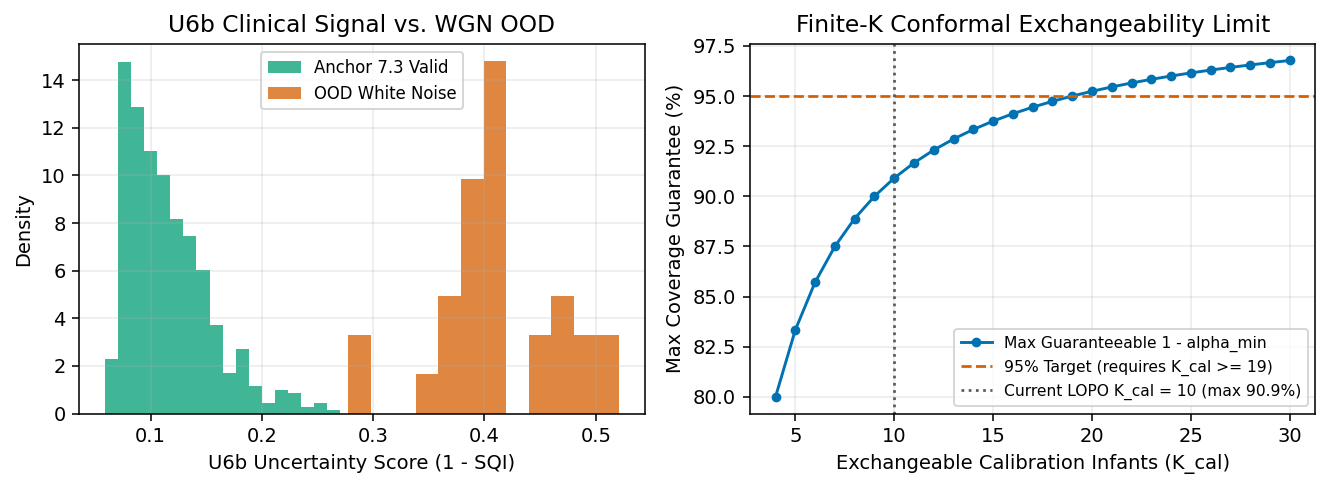

In [4]:
# U6b OOD contrast (Session 7.3 vs. WGN) & Finite-K Conformal Minimum Miscoverage Bound
phi_wgn = np.empty((30, VT.BR_GRID_1BPM.size, D.N_SAL_CHANNELS), dtype=np.float64)
for k in range(30):
    wgn = rng.normal(0.0, 1.0, size=480) + 1j * rng.normal(0.0, 1.0, size=480)
    dr = bandpass(wgn)
    dc = bandpass(mitigate_hpss(dr)["x_hat"])
    phi_wgn[k] = D.extract_salience_features_window(dr, dc, autocorr_coarse(dc), VT.BR_GRID_1BPM)
p_wgn = r2e.predict_session(phi_wgn)
u_wgn = UQ.extract_zero_tuned_proxies_session(phi_wgn, p_wgn["post_entropy"], p_wgn["post_sd_bpm"])

ks = np.arange(4, 31)
alpha_min = 1.0 / (ks + 1.0)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.6))
ax1.hist(u_73["U6b_ZeroTuned_Geometric_SQI"][valid], bins=18, density=True, alpha=0.75, color="#009E73", label="Anchor 7.3 Valid")
ax1.hist(u_wgn["U6b_ZeroTuned_Geometric_SQI"], bins=12, density=True, alpha=0.75, color="#D55E00", label="OOD White Noise")
ax1.set_xlabel("U6b Uncertainty Score (1 - SQI)")
ax1.set_ylabel("Density")
ax1.set_title("U6b Clinical Signal vs. WGN OOD")
ax1.legend(frameon=True, fontsize=8.5)
ax1.grid(alpha=0.25)

ax2.plot(ks, 100.0 * (1.0 - alpha_min), "o-", color="#0072B2", ms=4, label="Max Guaranteeable 1 - alpha_min")
ax2.axhline(95.0, color="#D55E00", ls="--", lw=1.4, label="95% Target (requires K_cal >= 19)")
ax2.axvline(10, color="#595959", ls=":", lw=1.4, label="Current LOPO K_cal = 10 (max 90.9%)")
ax2.set_xlabel("Exchangeable Calibration Infants (K_cal)")
ax2.set_ylabel("Max Coverage Guarantee (%)")
ax2.set_title("Finite-K Conformal Exchangeability Limit")
ax2.legend(loc="lower right", frameon=True, fontsize=8.0)
ax2.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [5]:
import json
raw = ROOT / "paper_orchestra_bundle" / "raw_materials"
s2 = json.loads((raw / "metrics_stage2_complexity.json").read_text())
s4 = json.loads((raw / "metrics_stage4_external.json").read_text())

print("Audited Headline Summary (pool30_sync NICU LOPO + gleichauf2024 External L4)")
print("-" * 74)
inb = s4["regimes"]["steady_state_excl_sync_pulses"]["inband_ge28bpm"]
skt = s4["regimes"]["steady_state_excl_sync_pulses"]["subband_20bpm_skirt"]
for label, key in [
    ("R0  HPSS+NLS (0p)", "R0_HPSS_NLS_Locked"),
    ("R2e FilterSafe-8 (8p)", "R2e_Causal_DiffHMM_FilterSafe8"),
    ("R3c Ridge (439p)", "R3c_Ridge_Spectral_439"),
    ("R3b MLP (14.6k)", "R3b_Spectral_MLP_15k"),
    ("R3a TCN (15.8k)", "R3a_Causal_TCN_16k"),
]:
    n1 = s2["cohorts"]["pool30_sync"]["br_1hz_30s"]["methods"][key]["rmse_sess"]
    nt = s2["cohorts"]["pool30_sync"]["br_trig_bpm_lag_aligned"]["methods"][key]["rmse_sess"]
    ei = inb[key]["rmse_scen"]
    es = skt[key]["rmse_scen"]
    print(f"{label:<22s} | 1Hz={n1:6.3f} | Trig-10s={nt:6.3f} | Ext InBand={ei:6.4f} | 20bpm Skirt={es:6.3f}")

Audited Headline Summary (pool30_sync NICU LOPO + gleichauf2024 External L4)
--------------------------------------------------------------------------
R0  HPSS+NLS (0p)      | 1Hz= 7.817 | Trig-10s= 8.727 | Ext InBand=0.0284 | 20bpm Skirt= 0.069
R2e FilterSafe-8 (8p)  | 1Hz= 6.849 | Trig-10s= 8.063 | Ext InBand=0.0197 | 20bpm Skirt= 0.095
R3c Ridge (439p)       | 1Hz= 5.798 | Trig-10s= 8.102 | Ext InBand=3.6353 | 20bpm Skirt=11.778
R3b MLP (14.6k)        | 1Hz= 6.584 | Trig-10s= 8.515 | Ext InBand=3.5022 | 20bpm Skirt=32.704
R3a TCN (15.8k)        | 1Hz= 6.075 | Trig-10s= 8.498 | Ext InBand=3.1782 | 20bpm Skirt=23.471
